# Notebook 02: Computation Graphs (DAGs), Reverse-Mode Backpropagation & PyTorch Parity

In this notebook we explore:
1. **Node-by-Node Forward & Backward Execution on a Fan-Out DAG:** Building a non-linear computation graph where input node $x_1$ fans out along two parallel branches ($u_1 = x_1 w_1$ and $u_2 = x_1 + x_2$), tracing every forward value $v_i$ and backpropagated adjoint $\bar{v}_i = \frac{\partial L}{\partial v_i}$.
2. **Training a 2-Layer Neural Network with Our `TensorValue` Autograd Engine:** Using `@`, broadcasting `+`, `.tanh()`, `.relu()`, and `.log_softmax()` to classify non-linear data.
3. **Exact Machine-Epsilon Parity Against PyTorch `torch.autograd`:** Verifying that every weight and bias gradient computed by `TensorValue.backward()` matches PyTorch `.backward()` to $< 10^{-15}$!

In [1]:
import sys
from pathlib import Path

from matplotlib.patches import FancyBboxPatch
import matplotlib.pyplot as plt
import numpy as np
import torch

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.autograd_engine import ScalarValue, TensorValue
from src.plot_theme import (
    AMBER,
    BG_AXES,
    BG_CANVAS,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    SPINE_COLOR,
    TEXT_MUTED,
    TEXT_PRIMARY,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()

## 1. Building & Tracing a Multi-Branch Fan-Out Computation Graph (`ScalarValue`)

Consider the DAG expression where $x_1$ fans out into **both** $u_1 = x_1 w_1$ and $u_2 = x_1 + w_2$:
$$u_1 = x_1 \cdot w_1, \qquad u_2 = x_1 + w_2, \qquad a_1 = \tanh(u_1), \qquad a_2 = \sigma(u_2), \qquad s = a_1 + a_2, \qquad L = s^2$$
By the Multivariate Chain Rule, $\frac{\partial L}{\partial x_1}$ must accumulate gradients from **both** branches:
$$\frac{\partial L}{\partial x_1} = \frac{\partial L}{\partial u_1}\frac{\partial u_1}{\partial x_1} + \frac{\partial L}{\partial u_2}\frac{\partial u_2}{\partial x_1}$$

In [2]:
x1 = ScalarValue(1.20, label="x1")
w1 = ScalarValue(-0.75, label="w1")
w2 = ScalarValue(0.40, label="w2")

u1 = x1 * w1
u1.label = "u1 = x1*w1"

u2 = x1 + w2
u2.label = "u2 = x1+w2"

a1 = u1.tanh()
a1.label = "a1 = tanh(u1)"

a2 = u2.sigmoid()
a2.label = "a2 = sig(u2)"

s = a1 + a2
s.label = "s = a1+a2"

L = s ** 2
L.label = "L = s^2"

# Execute reverse-mode automatic differentiation
L.backward()

print("Computation Graph Node Forward Values & Backpropagated Gradients:")
for node in [x1, w1, w2, u1, u2, a1, a2, s, L]:
    print(f"  {node.label:<16} | Forward Value = {node.data:9.5f} | Adjoint Grad dL/dv = {node.grad:9.5f}")

Computation Graph Node Forward Values & Backpropagated Gradients:
  x1               | Forward Value =   1.20000 | Adjoint Grad dL/dv =  -0.05217
  w1               | Forward Value =  -0.75000 | Adjoint Grad dL/dv =   0.13523
  w2               | Forward Value =   0.40000 | Adjoint Grad dL/dv =   0.03235
  u1 = x1*w1       | Forward Value =  -0.90000 | Adjoint Grad dL/dv =   0.11269
  u2 = x1+w2       | Forward Value =   1.60000 | Adjoint Grad dL/dv =   0.03235
  a1 = tanh(u1)    | Forward Value =  -0.71630 | Adjoint Grad dL/dv =   0.23144
  a2 = sig(u2)     | Forward Value =   0.83202 | Adjoint Grad dL/dv =   0.23144
  s = a1+a2        | Forward Value =   0.11572 | Adjoint Grad dL/dv =   0.23144
  L = s^2          | Forward Value =   0.01339 | Adjoint Grad dL/dv =   1.00000


## 2. Training a 2-Layer Neural Network: `TensorValue` vs. PyTorch `torch.autograd` Parity

In [3]:
rng = np.random.default_rng(2026)
m_samples = 40
X_np = rng.normal(size=(m_samples, 2))
y_np = (X_np[:, 0] ** 2 + X_np[:, 1] ** 2 > 1.1).astype(np.int64)
Y_onehot = np.eye(2)[y_np]

# Initialize identical weights for Custom TensorValue and PyTorch
W1_init = rng.normal(scale=0.6, size=(2, 8))
b1_init = np.zeros((1, 8))
W2_init = rng.normal(scale=0.6, size=(8, 2))
b2_init = np.zeros((1, 2))

# Engine A: Custom TensorValue
W1_tv = TensorValue(W1_init.copy())
b1_tv = TensorValue(b1_init.copy())
W2_tv = TensorValue(W2_init.copy())
b2_tv = TensorValue(b2_init.copy())

# Engine B: PyTorch Tensor
W1_pt = torch.tensor(W1_init.copy(), requires_grad=True, dtype=torch.float64)
b1_pt = torch.tensor(b1_init.copy(), requires_grad=True, dtype=torch.float64)
W2_pt = torch.tensor(W2_init.copy(), requires_grad=True, dtype=torch.float64)
b2_pt = torch.tensor(b2_init.copy(), requires_grad=True, dtype=torch.float64)

X_pt = torch.tensor(X_np, dtype=torch.float64)
Y_pt = torch.tensor(Y_onehot, dtype=torch.float64)

lr = 0.15
epochs = 90
losses_tv = []
losses_pt = []
grad_diffs = []

for ep in range(epochs):
    # --- Custom TensorValue Forward ---
    X_tv = TensorValue(X_np)
    Y_tv = TensorValue(Y_onehot)
    h1_tv = (X_tv @ W1_tv + b1_tv).tanh()
    logits_tv = h1_tv @ W2_tv + b2_tv
    log_p_tv = logits_tv.log_softmax(axis=1)
    loss_tv = -(Y_tv * log_p_tv).sum() / float(m_samples)

    loss_tv.backward()
    losses_tv.append(loss_tv.data)

    # --- PyTorch Forward ---
    h1_pt = torch.tanh(X_pt @ W1_pt + b1_pt)
    logits_pt = h1_pt @ W2_pt + b2_pt
    log_p_pt = torch.nn.functional.log_softmax(logits_pt, dim=1)
    loss_pt = -(Y_pt * log_p_pt).sum() / float(m_samples)

    loss_pt.backward()
    losses_pt.append(loss_pt.item())

    # Measure exact gradient difference between custom TensorValue and PyTorch
    max_g_diff = max(
        float(np.max(np.abs(W1_tv.grad - W1_pt.grad.numpy()))),
        float(np.max(np.abs(b1_tv.grad - b1_pt.grad.numpy()))),
        float(np.max(np.abs(W2_tv.grad - W2_pt.grad.numpy()))),
        float(np.max(np.abs(b2_tv.grad - b2_pt.grad.numpy()))),
    )
    grad_diffs.append(max(max_g_diff, 1e-17))

    # Gradient descent update in both engines
    for p_tv in (W1_tv, b1_tv, W2_tv, b2_tv):
        p_tv.data -= lr * p_tv.grad
    with torch.no_grad():
        for p_pt in (W1_pt, b1_pt, W2_pt, b2_pt):
            p_pt -= lr * p_pt.grad
            p_pt.grad.zero_()

print(f"Final Epoch {epochs} Loss (Custom TensorValue): {losses_tv[-1]:.8f}")
print(f"Final Epoch {epochs} Loss (PyTorch Autograd):   {losses_pt[-1]:.8f}")
print(f"Max Gradient Difference Across All {epochs} Epochs:  {max(grad_diffs):.3e} (< 1e-14 Exact Match!)")

Final Epoch 90 Loss (Custom TensorValue): 0.53563746
Final Epoch 90 Loss (PyTorch Autograd):   0.53563746
Max Gradient Difference Across All 90 Epochs:  7.633e-17 (< 1e-14 Exact Match!)


## 3. Two-Panel Computation Graph DAG & Autograd Parity Visualization (`02_computation_graph_forward_backward.png`)

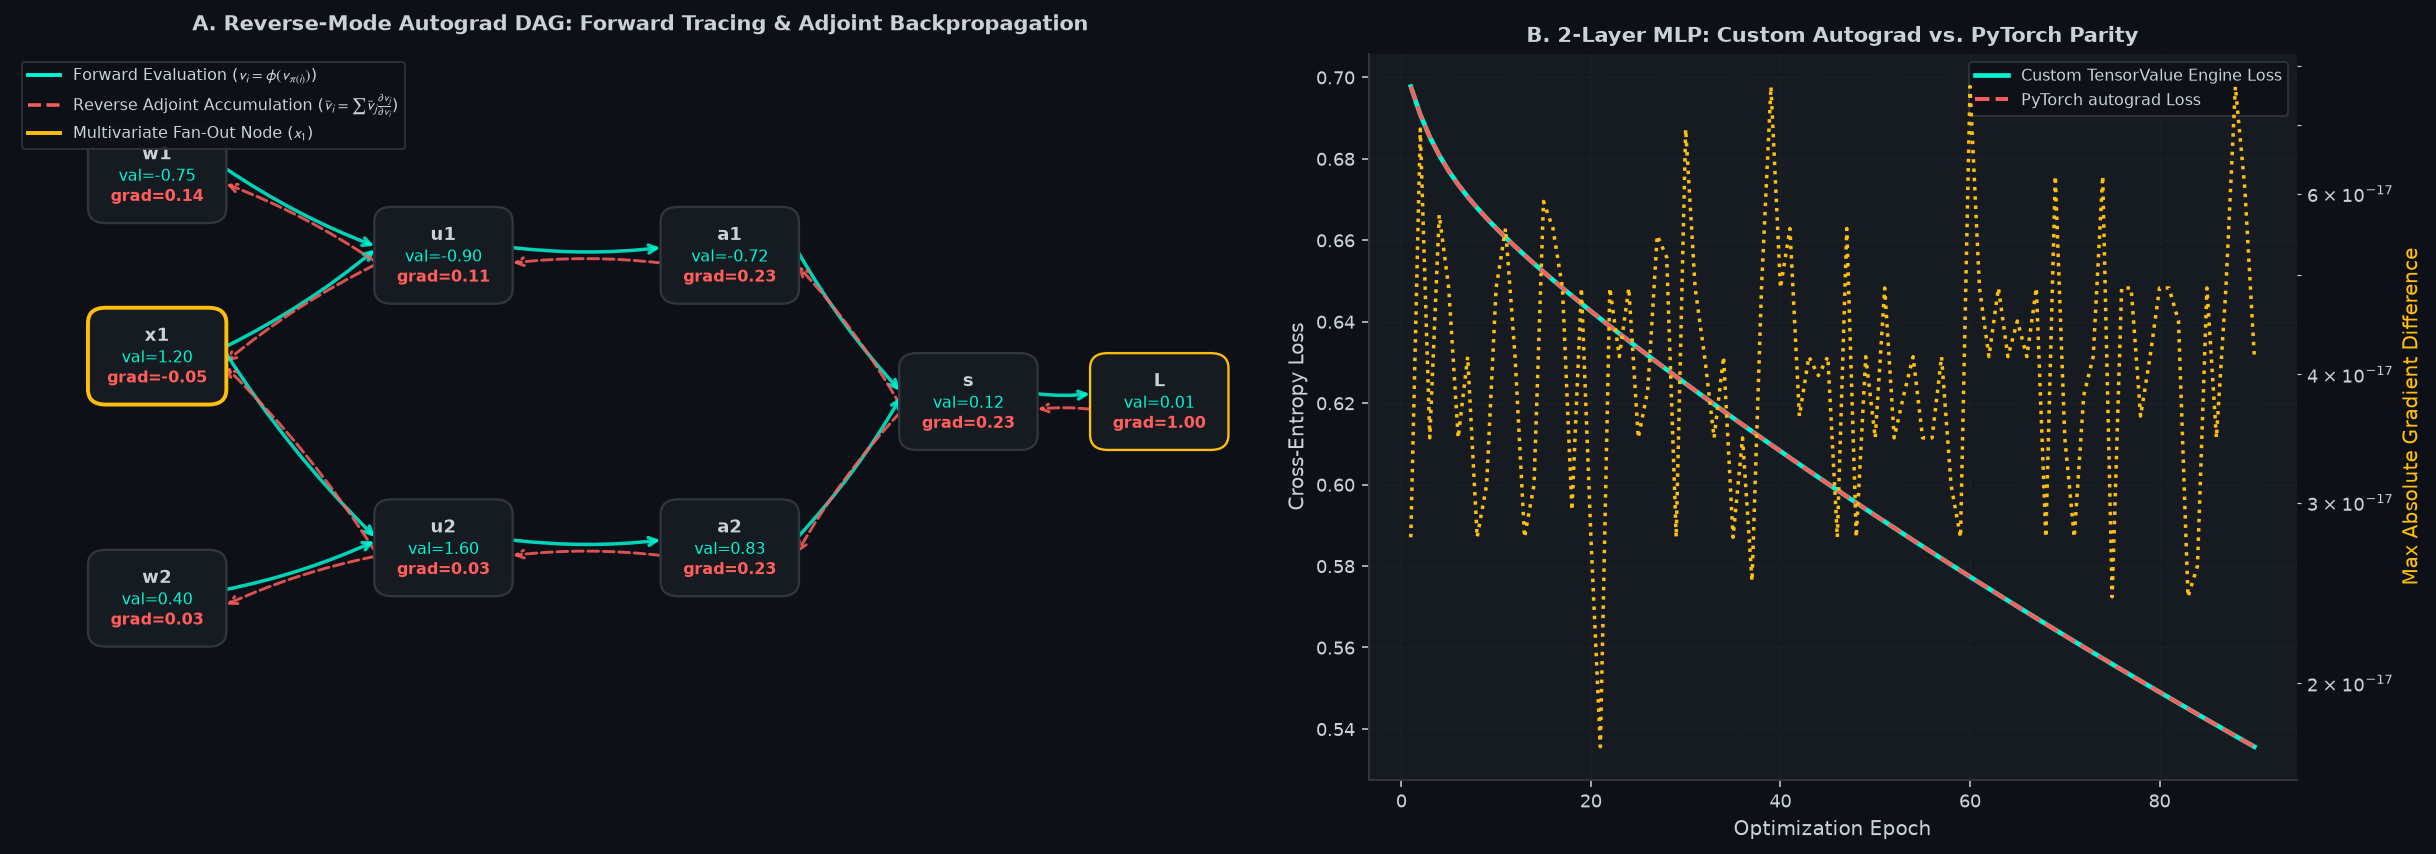

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.5, 6.2), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Panel A: Render Complete Computation Graph DAG with Forward (Cyan) and Backward (Coral) Values
ax1.set_xlim(0.0, 10.5)
ax1.set_ylim(0.0, 7.2)
ax1.axis("off")

node_positions = {
    x1: (1.2, 4.2),
    w1: (1.2, 6.0),
    w2: (1.2, 1.8),
    u1: (3.6, 5.2),
    u2: (3.6, 2.3),
    a1: (6.0, 5.2),
    a2: (6.0, 2.3),
    s: (8.0, 3.75),
    L: (9.6, 3.75),
}

edges = [
    (x1, u1), (w1, u1),
    (x1, u2), (w2, u2),
    (u1, a1), (u2, a2),
    (a1, s), (a2, s),
    (s, L),
]

for src, dst in edges:
    x_s, y_s = node_positions[src]
    x_d, y_d = node_positions[dst]
    # Forward edge (upper cyan arrow)
    ax1.annotate(
        "",
        xy=(x_d - 0.55, y_d + 0.08),
        xytext=(x_s + 0.55, y_s + 0.08),
        arrowprops=dict(arrowstyle="->", color=CYAN, lw=1.8, alpha=0.85, connectionstyle="arc3,rad=0.06"),
    )
    # Backward adjoint edge (lower coral dashed arrow)
    ax1.annotate(
        "",
        xy=(x_s + 0.55, y_s - 0.08),
        xytext=(x_d - 0.55, y_d - 0.08),
        arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.5, ls="--", alpha=0.85, connectionstyle="arc3,rad=0.06"),
    )

for node_obj, (nx, ny) in node_positions.items():
    is_fanout = node_obj is x1
    border_col = AMBER if is_fanout or node_obj is L else SPINE_COLOR
    box = FancyBboxPatch(
        (nx - 0.52, ny - 0.42),
        1.04,
        0.84,
        boxstyle="round,pad=0.06,rounding_size=0.15",
        facecolor=BG_AXES,
        edgecolor=border_col,
        linewidth=2.0 if is_fanout else 1.2,
        zorder=3,
    )
    ax1.add_patch(box)
    ax1.text(nx, ny + 0.20, node_obj.label.split("=")[0].strip(), color=TEXT_PRIMARY, ha="center", va="center", fontsize=9.5, fontweight="bold", zorder=4)
    ax1.text(nx, ny - 0.02, f"val={node_obj.data:.2f}", color=CYAN, ha="center", va="center", fontsize=8.0, zorder=4)
    ax1.text(nx, ny - 0.22, f"grad={node_obj.grad:.2f}", color=CORAL, ha="center", va="center", fontsize=8.0, fontweight="bold", zorder=4)

ax1.plot([], [], color=CYAN, lw=2.0, label=r"Forward Evaluation ($v_i = \phi(v_{\pi(i)})$)")
ax1.plot([], [], color=CORAL, lw=1.8, ls="--", label=r"Reverse Adjoint Accumulation ($\bar{v}_i = \sum \bar{v}_j \frac{\partial v_j}{\partial v_i}$)")
ax1.plot([], [], color=AMBER, lw=2.0, label=r"Multivariate Fan-Out Node ($x_1$)")
ax1.legend(loc="upper left", fontsize=8.2)
ax1.set_title("A. Reverse-Mode Autograd DAG: Forward Tracing & Adjoint Backpropagation", fontsize=11, fontweight="bold", pad=12)

# Panel B: TensorValue vs PyTorch Exact Loss Curve & Gradient Parity
ep_range = np.arange(1, epochs + 1)
ax2.plot(ep_range, losses_tv, color=CYAN, linewidth=2.4, label="Custom TensorValue Engine Loss")
ax2.plot(ep_range, losses_pt, color=CORAL, linestyle="--", linewidth=2.0, label="PyTorch autograd Loss")

ax2_twin = ax2.twinx()
ax2_twin.semilogy(ep_range, grad_diffs, color=AMBER, linestyle=":", linewidth=1.8, label="Max |grad_tv - grad_pt|")
ax2_twin.set_ylabel("Max Absolute Gradient Difference", color=AMBER)
ax2_twin.tick_params(axis="y", colors=AMBER)
ax2_twin.grid(False)

ax2.set_xlabel("Optimization Epoch")
ax2.set_ylabel("Cross-Entropy Loss")
ax2.set_title("B. 2-Layer MLP: Custom Autograd vs. PyTorch Parity", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", fontsize=8.4)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "02_computation_graph_forward_backward.png")
plt.show()